# 03 - Analise principal

Este notebook executa as analises textuais e mostra os relatorios/figuras principais.

Foco para a apresentacao: o aprendizado com os bancos de dados foi que a etapa de limpeza muda a interpretacao. Linux parecia menor quando algumas respostas estavam em `Other`; depois da normalizacao correta, Linux cresce no Stack Overflow.

In [3]:
from pathlib import Path
import subprocess
import sys
from IPython.display import Markdown, Image, display

def find_project_root(start=Path.cwd()):
    for path in (start, *start.parents):
        if (path / 'src').exists() and (path / 'data').exists():
            return path
    raise RuntimeError('Abra o notebook dentro do projeto os-data-project.')

root = find_project_root()
print(root)

/home/vini/Documentos/projetos/adoção-custo-de-so/os-data-project


## Analises A-G

Esta celula roda o script textual principal. Ela mostra tabelas sobre sistemas operacionais, pais, Brasil, experiencia, comparacao com StatCounter e validacoes basicas.

In [4]:
subprocess.run([sys.executable, str(root / 'src' / 'analyze.py')], cwd=root, check=True)

Denominador dos percentuais Stack Overflow: respondentes com resposta valida de sistema operacional no ano.
Respostas multi-select podem gerar mais de um sistema por respondente; percentuais podem somar mais de 100%.

=== A. Sistemas mais frequentes entre desenvolvedores ===
sistema | selecoes
--- | ---
Windows | 158483
Linux | 132293
macOS | 81374
Other | 40704
ChromeOS | 1984
BSD | 1657

=== B. Evolucao Windows, Linux e macOS ===
ano | familia | respondentes | pct
--- | --- | --- | ---
2022 | Linux | 28523 | 43.54
2022 | Windows | 36674 | 55.99
2022 | macOS | 23578 | 36.0
2023 | Linux | 35906 | 45.69
2023 | Windows | 42844 | 54.52
2023 | macOS | 28786 | 36.63
2024 | Linux | 25167 | 47.51
2024 | Windows | 29365 | 55.43
2024 | macOS | 18625 | 35.16
2025 | Linux | 14649 | 50.72
2025 | Windows | 16215 | 56.14
2025 | macOS | 10385 | 35.96

=== C. Diferenca por pais - top combinacoes ===
pais | familia | respondentes
--- | --- | ---
United States of America | Windows | 22777
United States 

CompletedProcess(args=['/home/vini/Documentos/projetos/adoção-custo-de-so/os-data-project/.venv/bin/python', '/home/vini/Documentos/projetos/adoção-custo-de-so/os-data-project/src/analyze.py'], returncode=0)

## Investigacao da mudanca do Linux

Este relatorio explica a descoberta central: parte do Linux estava escondida em `Other`.

In [5]:
trend_report = root / 'reports' / 'trend_investigation.md'
display(Markdown(trend_report.read_text(encoding='utf-8')))

# Investigação de tendência

## 1. Descobertas encontradas

1. Linux teve a maior mudança clara após corrigir a normalização: passou de 43.54% em 2022 para 50.72% em 2025 (+7.17 p.p.).
2. Windows ficou praticamente estável no período completo: 55.99% em 2022 e 56.14% em 2025 (+0.15 p.p.).
3. macOS também ficou quase estável: 36.00% em 2022 e 35.96% em 2025 (-0.04 p.p.).

## 2. Descoberta escolhida

A descoberta escolhida foi que a primeira leitura dos dados subestimava Linux porque algumas respostas claramente relacionadas a Linux estavam caindo em `Other`.

Ela foi escolhida porque mostra um ponto central de mineração de dados: antes de interpretar uma tendência, é preciso auditar a qualidade da normalização. Depois da correção, Linux deixa de parecer queda e passa a ser a maior alta entre os três sistemas.

## 3. Evidência no Stack Overflow

Ano | Windows | Linux | macOS | Respondentes válidos
--- | --- | --- | --- | ---
2022 | 36.674 (55.99%) | 28.523 (43.54%) | 23.578 (36.00%) | 65.503
2023 | 42.844 (54.52%) | 35.906 (45.69%) | 28.786 (36.63%) | 78.587
2024 | 29.365 (55.43%) | 25.167 (47.51%) | 18.625 (35.16%) | 52.973
2025 | 16.215 (56.14%) | 14.649 (50.72%) | 10.385 (35.96%) | 28.883

Os percentuais usam como denominador os respondentes que responderam validamente à pergunta de sistema operacional naquele ano. Como a pergunta permite respostas múltiplas, os percentuais podem somar mais de 100%.

Diferença em pontos percentuais entre anos:

Ano | Sistema | Diferença vs. ano anterior
--- | --- | ---
2023 | Windows | -1.47 p.p.
2023 | Linux | +2.14 p.p.
2023 | macOS | +0.63 p.p.
2024 | Windows | +0.92 p.p.
2024 | Linux | +1.82 p.p.
2024 | macOS | -1.47 p.p.
2025 | Windows | +0.71 p.p.
2025 | Linux | +3.21 p.p.
2025 | macOS | +0.80 p.p.

## 4. Hipóteses

1. A alta de Linux pode representar aumento real de uso entre respondentes do Stack Overflow.
2. Parte da mudança pode estar ligada à forma como as opções do survey aparecem nos anos mais recentes.
3. Parte da mudança pode estar ligada à normalização: distribuições ou variantes Linux precisam ser agrupadas na família Linux.
4. A tendência dos desenvolvedores pode ser diferente da tendência do mercado desktop geral.

## 5. Hipótese investigada

A hipótese investigada foi: a aparente queda inicial de Linux era um artefato de preparação dos dados. Ao reclassificar respostas explicitamente Linux, como `Other Linux-based`, `Linux (non-WSL)`, `Red Hat`, `NixOS` e `Pop!_OS`, a tendência correta mostra crescimento de Linux entre os respondentes.

## 6. Fontes externas

- nome: StackExchange/Survey - arquivos oficiais do Stack Overflow Developer Survey
- link: https://github.com/StackExchange/Survey/tree/main/packages/archive
- data: consultado em 2026-09-13
- dado ou fato encontrado: o repositório oficial mantém, por ano, `results.csv` e `schema.csv`; os schemas registram a pergunta `OpSys` sobre o sistema operacional primário usado no trabalho.
- relação com a hipótese: confirma que a análise usa arquivos oficiais e que a pergunta de sistema operacional vem do survey original.

- nome: Valores originais encontrados nos CSVs do Stack Overflow
- link: dados locais extraídos dos `results.csv` oficiais
- data: consultado em 2026-09-13
- dado ou fato encontrado: foram encontradas 26.268 seleções em valores explicitamente Linux que precisavam ficar na família Linux.
- relação com a hipótese: esses valores explicam por que a classificação anterior jogava parte do Linux em `Other`.

- nome: StatCounter Desktop OS Market Share Worldwide
- link: https://gs.statcounter.com/os-market-share/desktop/worldwide
- data: consultado em 2026-09-13
- dado ou fato encontrado: nos dados coletados pelo projeto, Linux no mercado desktop geral passou de 2.69% em 2022 para 4.16% em 2025 (+1.47 p.p.).
- relação com a hipótese: a direção do StatCounter também é de crescimento, embora em outro público e com outra metodologia.

- nome: StatCounter FAQ / metodologia
- link: https://gs.statcounter.com/faq
- data: consultado em 2026-09-13
- dado ou fato encontrado: o StatCounter calcula estatísticas a partir de page views em mais de 1 milhão de sites e mais de 3 bilhões de page views por mês, analisando sistema operacional por page view.
- relação com a hipótese: mostra que o StatCounter mede mercado/uso web geral, uma população diferente do Stack Overflow.

## 7. Comparação

Valores originais reclassificados como Linux:

Ano | Valor original | Seleções
--- | --- | ---
2023 | Other Linux-based | 6.712
2023 | Red Hat | 4.043
2024 | Other Linux-based | 4.697
2024 | Red Hat | 2.858
2025 | Linux (non-WSL) | 5.261
2025 | Red Hat | 1.789
2025 | NixOS | 570
2025 | Pop!_OS | 338

Tabela externa do StatCounter, média anual no mercado desktop geral:

Ano | Windows | Linux | macOS
--- | --- | --- | ---
2022 | 79.05% | 2.69% | 7.93%
2023 | 73.18% | 3.24% | 9.98%
2024 | 77.34% | 4.38% | 8.03%
2025 | 77.76% | 4.16% | 8.19%

Linha do tempo:

2022
- Stack Overflow Linux: 43.54%
- Stack Overflow Windows: 55.99%
- StatCounter Linux desktop: 2.69%

2023
- Stack Overflow Linux: 45.69%
- Stack Overflow Windows: 54.52%
- StatCounter Linux desktop: 3.24%
- Fato relevante: aparecem valores como `Other Linux-based` e `Red Hat`, que precisam ser tratados como Linux.

2024
- Stack Overflow Linux: 47.51%
- Stack Overflow Windows: 55.43%
- StatCounter Linux desktop: 4.38%
- Fato relevante: `Other Linux-based` e `Red Hat` continuam aparecendo entre os valores originais.

2025
- Stack Overflow Linux: 50.72%
- Stack Overflow Windows: 56.14%
- StatCounter Linux desktop: 4.16%
- Fato relevante: aparece `Linux (non-WSL)`, além de distribuições como `NixOS` e `Pop!_OS`.

Os dados apoiam a hipótese de que havia um problema de preparação: tokens explicitamente Linux estavam fora da família Linux. Depois da correção, Linux cresce no Stack Overflow de 43.54% para 50.72%. O StatCounter também mostra crescimento de Linux no desktop geral, mas essa comparação é apenas contextual porque as fontes medem populações diferentes.

## 8. Conclusão

Nos dados corrigidos do Stack Overflow, Linux cresceu de 43.54% em 2022 para 50.72% em 2025. Essa é a tendência mais interessante entre os três sistemas analisados.

O ponto principal da investigação é que a conclusão anterior seria enganosa sem auditar `Other`. O crescimento fica claro depois que variantes Linux são classificadas corretamente. A comparação com o StatCounter reforça que Linux também cresce no mercado desktop geral, mas não prova que as duas tendências tenham a mesma causa.

## 9. Limitações

- A análise não prova causalidade.
- Stack Overflow representa respondentes da comunidade de desenvolvimento, não todos os usuários de computador.
- StatCounter mede page views em sites participantes, não respondentes individuais.
- StatCounter e Stack Overflow medem populações diferentes.
- Respostas de sistema operacional podem permitir múltiplos sistemas; por isso os percentuais podem somar mais de 100%.
- Mudanças de schema e de formulação de perguntas entre anos podem afetar comparações.
- A reclassificação cobre apenas valores explicitamente Linux encontrados nos dados; outros valores em `Other` devem continuar sendo tratados com cautela.

## 10. Roteiro para apresentação

Quando exploramos nossa base, primeiro parecia que Linux tinha caído. Mas isso ficou estranho, então auditamos a categoria `Other`. Nessa auditoria encontramos respostas como `Other Linux-based`, `Linux (non-WSL)`, `Red Hat`, `NixOS` e `Pop!_OS`, que são claramente ligadas a Linux.

Depois de corrigir a normalização, Linux passou de 43.54% em 2022 para 50.72% em 2025, uma alta de +7.17 p.p.. Windows e macOS ficaram quase estáveis no mesmo período.

Para comparar com uma fonte externa, usamos o StatCounter. Lá, Linux no mercado desktop geral também aumentou, de 2.69% em 2022 para 4.16% em 2025. Essa comparação ajuda como contexto, mas não prova causalidade porque StatCounter e Stack Overflow medem populações diferentes.

Nossa conclusão é que a descoberta principal não é apenas que Linux cresceu. A descoberta mais importante é metodológica: sem limpar corretamente os valores originais, parte do Linux ficava escondida em `Other` e a interpretação ficava errada. Isso mostra por que a preparação dos dados é uma etapa essencial antes da análise.


## Grafico principal

Este grafico e o melhor print para explicar a mudanca depois da limpeza.

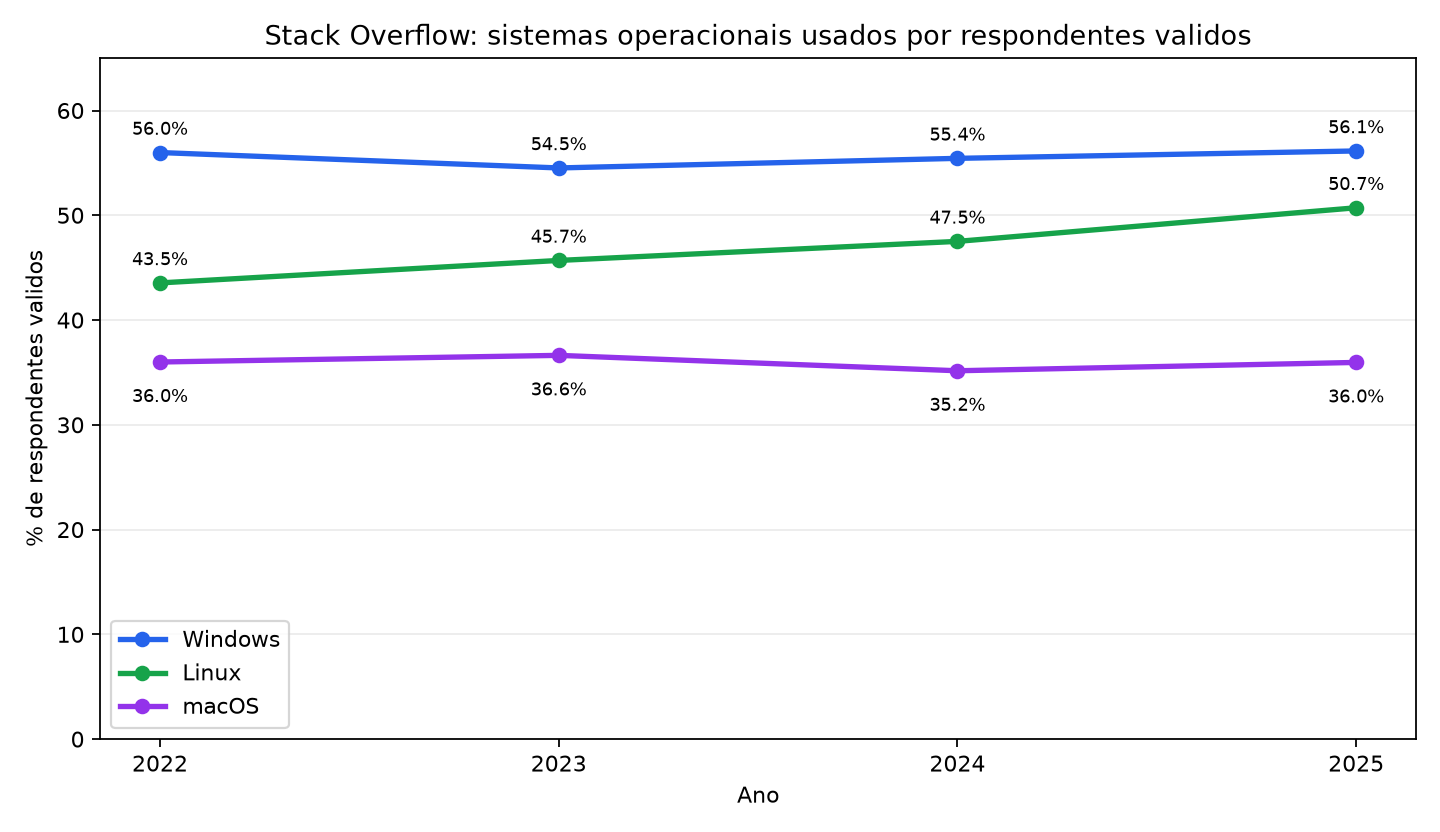

In [6]:
display(Image(filename=str(root / 'reports' / 'figures' / '06_trend_investigation.png')))

## Fonte gamer complementar

A Steam nao substitui o Stack Overflow. Ela entra para comparar a tendencia em outro publico: usuarios da Steam/gamers.

# Tendencia Linux entre gamers

## Fonte

A fonte gamer escolhida foi a Steam Hardware & Software Survey, pesquisa mensal oficial da Valve/Steam:

```text
https://store.steampowered.com/hwsurvey/Steam-Hardware-Software-Survey-Welcome-to-Steam
```

Para ter historico em CSV, foi usado o repositorio publico `jdegene/steamHWsurvey`, que organiza dados da Steam Hardware Survey e dados antigos via Web Archive:

```text
https://github.com/jdegene/steamHWsurvey
```

Arquivos CSV consultados:

- `shs.csv`: 4.10 MB
- `shs_platform.csv`: 26.99 MB

## Metodo

A Steam mostra versoes especificas de sistema operacional na pagina geral, mas parte das versoes pode ficar escondida em `Other` ou nao aparecer no resumo principal. Por isso, esta verificacao nao soma apenas as versoes visiveis.

O calculo cruza as versoes visiveis no CSV geral com a pagina especifica de cada plataforma. Exemplo: se as distros Linux visiveis no resumo representam uma parte conhecida dentro da pagina Linux, essa proporcao e usada para estimar o total Linux.

## Resultado principal

Linux entre usuarios da Steam aumentou no periodo analisado:

- 2022-12: 1.38%
- 2025-12: 3.57%
- variacao: +2.19 p.p.
- crescimento relativo: 2.58x

Esse resultado combina com a tendencia corrigida do Stack Overflow: em outro publico, tambem aparece crescimento de Linux. A comparacao deve ser usada como evidencia complementar, nao como prova de causalidade.

## Dezembro de cada ano

Ano | Windows | Linux | macOS
--- | --- | --- | ---
2022 | 96.14% | 1.38% | 2.45%
2023 | 96.41% | 1.94% | 1.62%
2024 | 96.33% | 2.05% | 1.40%
2025 | 94.23% | 3.57% | 2.19%

## Ultimo mes disponivel no historico

- Mes: 2026-08
- Linux: 3.89%

## Interpretacao para o seminario

A conclusao que podemos defender e: depois da correcao da normalizacao, Linux cresceu no Stack Overflow; e uma fonte externa de gamers, a Steam Hardware Survey, tambem mostra crescimento de Linux entre usuarios da Steam.

Isso fortalece a pergunta de pesquisa porque mostra que a alta nao apareceu apenas dentro da nossa base principal. Mesmo assim, cada fonte mede um publico diferente:

- Stack Overflow: respondentes desenvolvedores.
- StatCounter: uso desktop observado em page views.
- Steam: usuarios da Steam que participam da pesquisa de hardware/software.

## Limitacoes

- A Steam Survey e opcional e anonima.
- Os dados historicos em CSV vem de um repositorio publico que organiza dados da Steam e Web Archive; a fonte oficial principal e a pagina da Steam.
- Usuarios da Steam nao representam todos os gamers nem todos os usuarios de desktop.
- Os percentuais sao de participacao, nao quantidade absoluta de pessoas.
- Comparar Steam com Stack Overflow e StatCounter serve para contexto, nao para causalidade.

Gerado em 2026-09-13.


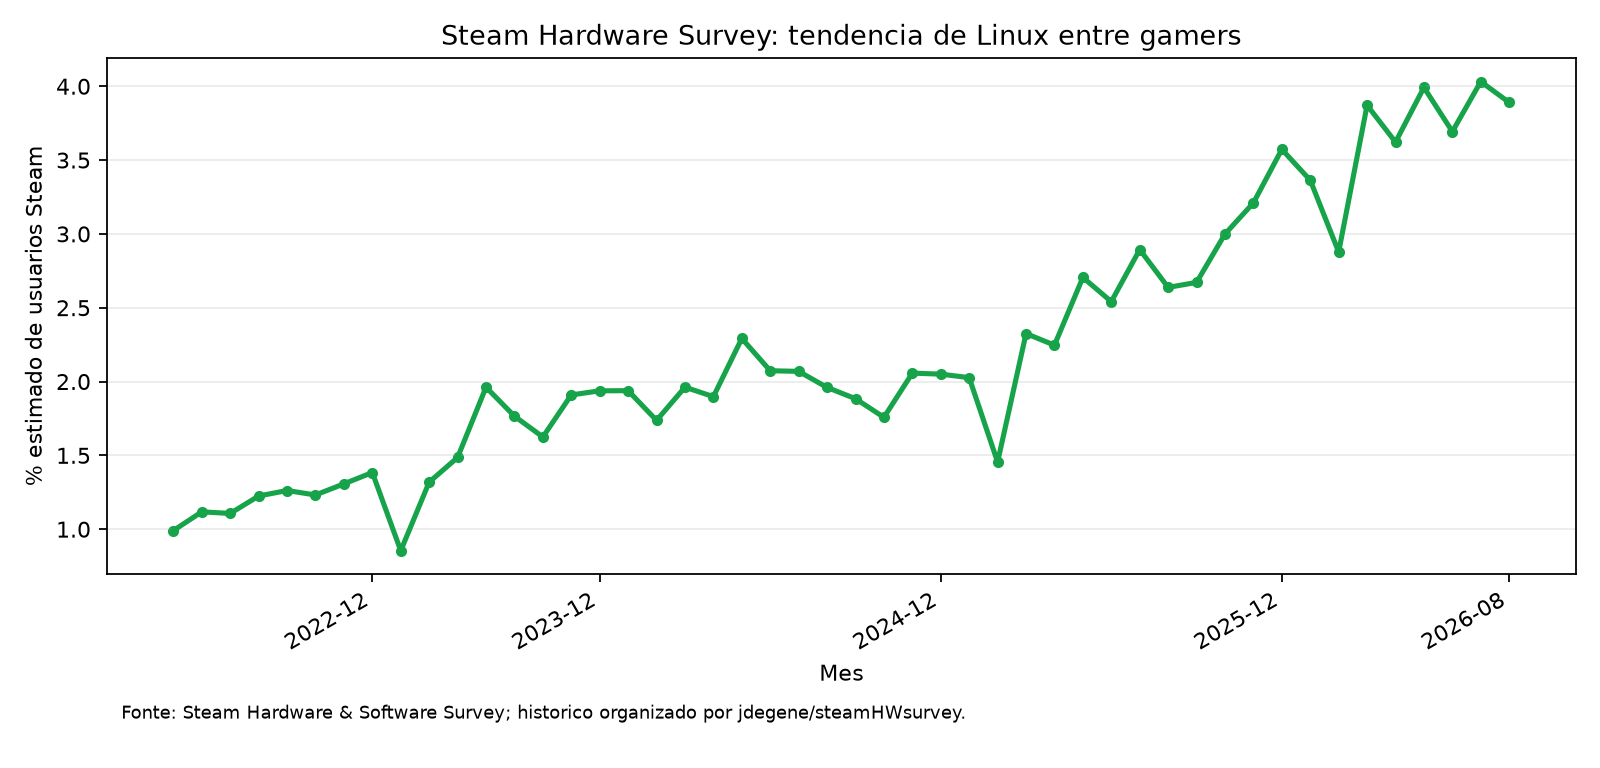

In [8]:
gaming_report = root / 'reports' / 'gaming_linux_trend.md'
display(Markdown(gaming_report.read_text(encoding='utf-8')))
display(Image(filename=str(root / 'reports' / 'figures' / '07_steam_linux_trend.png')))